# Data Science I - WS 2024/2025 - Praktikum III: Data Preprocessing - California Housing Datasets. 


**Regeln für das Praktikum:**
- Sie können die Aufgaben alleine oder zu zweit bearbeiten.
- Sie dürfen in Vorlesungs-Skripten nachlesen 
- Sollten Fragen auftauchen, oder die Verwendung von Klassen unklar sein, schlagen Sie  die Dokumentation online nach
- Befolgen Sie einfach den Anweisungen im Skript; manchmal wird im Markdown Text eine Frage gestellt; tragen Sie Ihre Antwort in der nächsten Markdown-Zelle bei #TODO ein!
- Manchmal ist Code als auskommentierter Lückentext angegeben. Löschen Sie die Kommentarzeichen und vervollständigen Sie den Code!

**Hinweis:**

Wie in der Vorlesung verwenden wir für das Data Preprocessing in diesem Praktikum

* [pandas](https://pandas.pydata.org/docs/reference/)
* [Scikit Learn API](https://scikit-learn.org/stable/)


In diesen Praktikum arbeiten wir mit der **California Housing Dataset**: Es enthält die mittleren Preise für Häuser in Bezirken von Californien zusammen mit den geografischen Daten wie Längen- und Breitengrad und Nähe zum Meer, Zensus-Daten wie den Einwohnerzahlen in jedem Bezirk, der Gesamtanzahl von Räumen und Haushalten, sowie dem mittleren Einkommen in den Bezirken. 

**Langfristiges Ziel:** Wir wollen mit Hilfe dieser Daten herausfinden, wie man den mittleren Hauspreis von den anderen gegebenen Daten ableiten kann.

**Ziel dieses Praktikums:** Wir wollen Data Preprocessing wie in der Vorlesung besprochen durchführen (EDA, Data Cleaning, Feature Engineering, Pipelines & Transformers)

**Daten laden**:
Führen Sie die vorbefüllten Zellen aus, welche die Daten von "https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.tgz" in einen Unterordner "housing" von "datasets" im ML1-Prakikumsordner speichern, in dem sich auch dieses Notebook befindet. Dann werden die Daten geladen. 

In [29]:
# Import der notwendigen Dependencies
import os
# zum Entpacken von Dateien:
import tarfile
# zum Herunterladen von Dateien:
import urllib.request
# zum Bearbeiten von "DataFrames"
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt

DOWNLOAD_ROOT = "https://raw.githubusercontent.com/ageron/handson-ml/master/"
HOUSING_URL = DOWNLOAD_ROOT + "datasets/housing/housing.tgz"
HOUSING_PATH = os.path.join("datasets", "housing")

# Funktion zum Herunterladen der Daten
"""Optional Arguments: housing_url=HOUSING_URL, housing_path=HOUSING_PATH"""

def fetch_housing_data(housing_url=HOUSING_URL, housing_path=HOUSING_PATH):
    os.makedirs(housing_path, exist_ok=True)
    tgz_path = os.path.join(housing_path, "housing.tgz")
    urllib.request.urlretrieve(housing_url, tgz_path)
    housing_tgz = tarfile.open(tgz_path)
    housing_tgz.extractall(path=housing_path)
    housing_tgz.close()

In [30]:
fetch_housing_data()

In [31]:
# Funktion zum Lade der Daten
"""Optional Argument: housing_path=HOUSING_PATH"""

def load_housing_data(housing_path=HOUSING_PATH): 
    csv_path = os.path.join(housing_path, "housing.csv")
    return pd.read_csv(csv_path)

housing = load_housing_data()

### 1. Schritt: Exploratory Data Analysis 

Der erste Schritt wenn man mit Daten arbeitet ist, diese so gut wie möglich kennen zu lernen und zu visualisieren. 

Holen Sie sich Informationen über den Datensatz "housing", indem Sie die Anweisungen der Kommentare unten befolgen: 

In [32]:
# Sehen Sie sich die ersten Zeilen der Tabelle mit .head() an.
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Was ist ein Instance des Datensatzes?

Die Instance ist die Input-Data bzw. das Sample.

In [33]:
# Holen Sie sich die grundlegenden Infos über die Daten mit .info()
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


Was sind die Features und das Label der Daten? Notieren Sie diese: 

Features: longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income, median_house_value, ocean_proximity

Label/Outcome: Wir wollen den mittleren Hauspreis bestimmen.

Welche Features sind nicht numerisch? Sind diese ordinal oder nominal?

Numerisch: 
Ordinal:longitude, latitude, house_median_age, median_income, median_hause_value
Nominal: total_rooms, total_bedrooms, population, households

Nicht Numerisch:
ocean_proximity

Gibt es sogenannte Missing Values? Wenn ja, welche Features sind betroffen?

??????????????

Gibt es Duplikate?

In [34]:
# check duplicates
housing.duplicated().sum()

np.int64(0)

Es gibt keine Duplikate

## 1.1 Schritt : Explore each Feature

In [35]:
# Bestimmen Sie für alle kategorischen Daten 
# alle auftretenden Kategorien und ihre Häufigkeit 
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

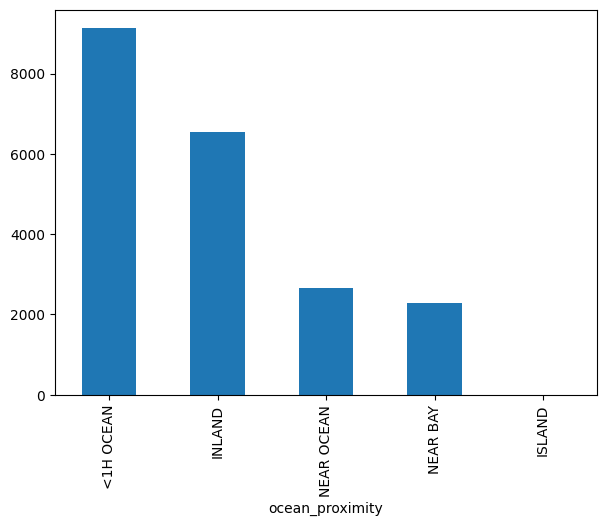

In [36]:
# Visualisieren Sie die obigen Ergebnisse
housing["ocean_proximity"].value_counts().plot(kind="bar", figsize = (7,5));

Frage: Können Sie an der Verteilung des Features "ocean_proximity" ein mögliches Problem erkennen was auftreten könnte?

DIe Aussagen sind genauer je näher die Häuser am Ocean sind.

In [37]:
# Lassen Sie sich die wichtigsten statistischen Daten 
# zu den einzelnen quantitativen Features ausgeben
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


Werfen Sie einen Blick auf den Mittelwert von total_rooms und total_bedrooms. Kann es sich hierbei um die Anzahl von Räumen je Haus handeln? Was beschreiben die Werte wohl? 

Die werte sind unrealistisch hoch. Es handelt sich vermutlich um die Zimmeer eines ganzen Bereichs der größe eines Dorfs.


Visualisieren Sie die Verteilung aller quantitativen Features in Form von Histogrammen, also die Unterteilung der Daten in diskrete Klassen und Anzeige der Häufigkeit jeder Klasse. 

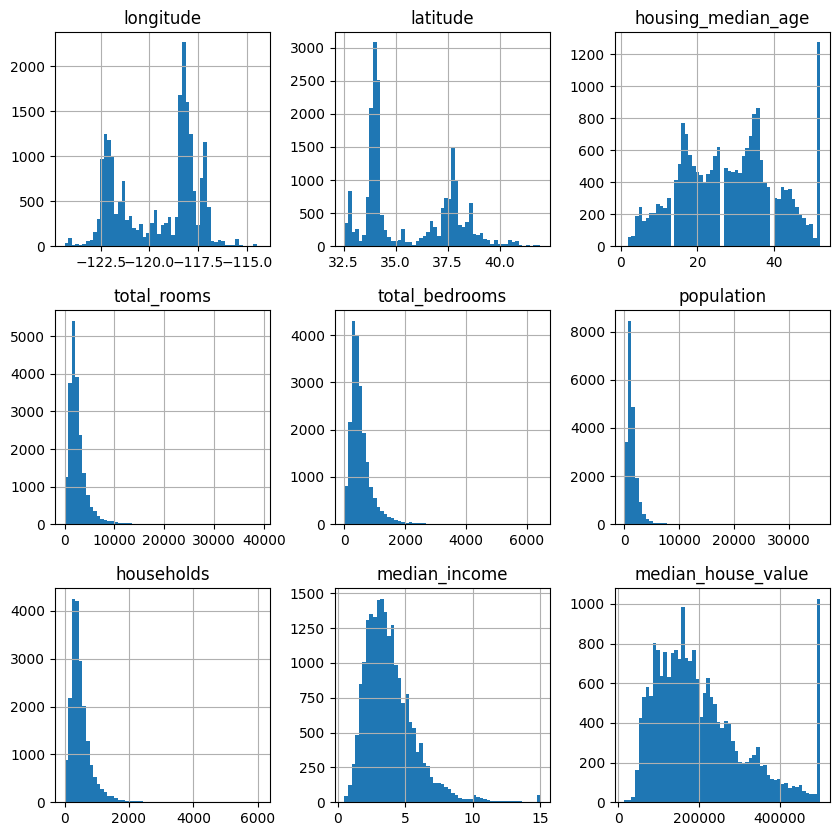

In [38]:
# Anzeige von Histogrammen der Features 
housing.hist(bins="rice", figsize = (10,10));

Lesen Sie von den Histograms ab, wo (longitude und latitude) die meisten districts sind. Googlen Sie, wo sich dieser Ort befindet.

Longitude: -118,2
latitude: 34

##  1.2 Schritt: Explore pairwise feature correlation

Bestimmen Sie zunächst wichtige statistische Daten für die Variable median_house_value in den verschiedenen Kategorien der Variable ocean_proximity durch (Class Breakdowns). 

In [39]:
# Class Breakdowns für median_house_value 
housing.groupby("ocean_proximity")["median_house_value"].describe()

,count,mean,std,min,25%,50%,75%,max
ocean_proximity,,,,,,,,
<1H OCEAN,9136.0,240084.285464,106124.292213,17500.0,164100.0,214850.0,289100.0,500001.0
INLAND,6551.0,124805.392001,70007.908494,14999.0,77500.0,108500.0,148950.0,500001.0
ISLAND,5.0,380440.000000,80559.561816,287500.0,300000.0,414700.0,450000.0,450000.0
NEAR BAY,2290.0,259212.311790,122818.537064,22500.0,162500.0,233800.0,345700.0,500001.0
NEAR OCEAN,2658.0,249433.977427,122477.145927,22500.0,150000.0,229450.0,322750.0,500001.0


<Axes: title={'center': 'median_house_value'}, xlabel='ocean_proximity'>

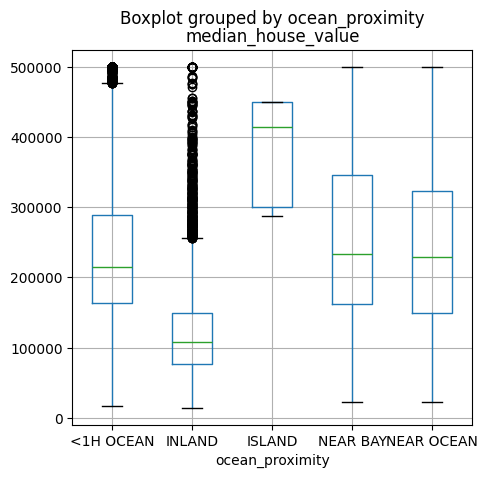

In [40]:
# Visualisieren Sie die statistischen Daten in den verschiedenen Kategorien
housing.boxplot(column=['median_house_value'], by="ocean_proximity", figsize=(5,5))

Können Sie einen Unterschied über die Klassen hinweg beobachten?

Der druchschnittliche Wert eines Hauses ist weitaus höher, je näher man zum Ocean wohnt.

Als nächstes berechnen wir die **Pearson's Korrelationsmatrix**. Achtung: ab pandas version 2.0.0 braucht man numeric_only=True um nur die numerischen Features auswerten zu lassen!

In [41]:
# Berechnen der Korrelationsmatrix
housing.corr(method="pearson", numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


Welche Spalte der Korrelationsmatrix ist die wichtige für unser Ziel, median_house_value zu prognostizieren? 

Der median_income trägt am meisten dazu bei.

Lassen Sie sich diese separat mit absteigenden Werten ausgeben in der nächsten Zelle.

In [42]:
housing.corr(method="pearson", numeric_only=True).median_house_value.sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

Welches Feature ist dasjenige, das am meisten mit median_house_value korreliert ist? 
Was bedeutet das?

median_income

Was ist das am wenigsten korrelierte Feature? Heißt das, dass es keine Abhängigkeit von diesem Feature gibt?

population

Visualisieren Sie die Abhängigkeit von median_house_value und diesem wichtigsten Feature in einem Scatterplot in der nächsten Zelle.

<Axes: xlabel='median_income', ylabel='median_house_value'>

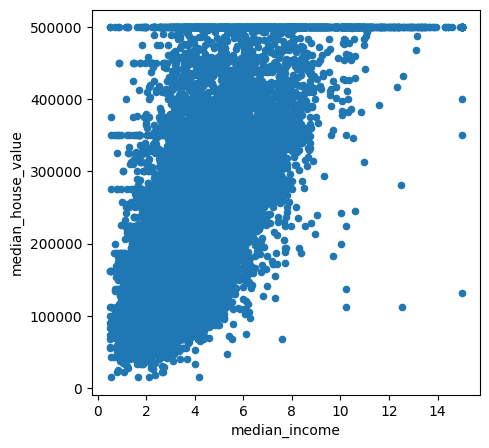

In [43]:
housing.plot.scatter(x='median_income', y='median_house_value',figsize=(5,5))

Was fällt auf und wie erklären Sie sich das? #TODO

Bei einem median_hause_value von 500000, gibt es einen Median_income von jedem Spektrum.

### 2. Schritt: Data Cleaning

#### Missing Values

Als nächstes kümmern wir uns um die fehlenden Werte. Wir haben bereits gesehen, wo Werte fehlen. 

##### Methoden, mit unvollständigen Daten umzugehen:

1. **Komplettes Feature löschen**: Wenn in einer Spalte sehr viele Werte nicht befüllt sind, kann es das beste sein, einfach die Spalte zu löschen und die Instances, die hier keinen Eintrag haben, zu behalten. (gut, wenn man wenige Daten hat und ein Feature systematisch schlecht befüllt ist)
2. **Unvollständige Instances löschen**: Hiermit kann man alle Instances aus dem Datensatz löschen, in denen ein Datensatz fehlt. Über die Option subset kann man einschränken, in welcher Spalte hier nach fehlenden Werten gesucht wird. Diese Option ist besser, wenn es nur wenig Instances gibt, die schlecht sind, und nicht systematisch eine ganze Spalte schlecht ist.
3. **Nichts löschen, sondern fehlende Werte ersetzen** generell eine bevorzugte Variante, weil man keine Instances oder Features verliert. 


In [44]:
#Wenden Sie 1. an und nutzen Sie '.drop()' um die betroffenen Features zu löschen
housing.drop(columns=["total_bedrooms"])

,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,741.0,349.0,1.8672,84700.0,INLAND


In [45]:
#Wenden Sie 2. an und nutzen Sie '.dropna()' um die betroffenen Bezirke zu löschen
housing.dropna(subset=["total_bedrooms"])

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [46]:
#Wenden Sie 3. an und nutzen Sie '.fillna()' um mit dem Median aufzufüllen
housing.fillna(housing["total_bedrooms"].median())


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


Für welche Methode würden Sie ablehnen?

Die drite Methode würde ich nicht nehmen, da der median nicht so viel aussagt wie die anderen Methoden.

**Unvollständige Daten ersetzen mit Scikit Learn:**

Wie in der Vorlesung schon gesehen, bietet Scikit Learn eine bequeme Lösung an, um fehlende Werte automatisch für alle (numerischen) Spalten durch jeweilige passenden Werte zu ersetzen: [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)

Sie müssen zunächst in Ihrer Umgebung scikit-learn installieren (zB. im Terminal "pip install scikit-learn")

Führen Sie analog zur Vorlesung folgende Schritte durch:
* Legen Sie bitte zuerste eine Kopie "housing_num" des DataFrames ohne das nicht-numerische Feature "ocean_proximity" an
* wenden sie in der nächsten Zelle den SimpleImputer auf diese Kopie an mit
    * .fit (berechnet die Zentralwerte)
    * .transform (ersetzt die fehlenden Daten mit den Zentralwerten)
    * .fit_transform (beides in einem Schritt)
* Das Ergebnis ist ein numpy ndarray. Verwandeln Sie es wieder in ein pandas Dataframe "housing_num_imputed".  

In [47]:
# Ergänzen Sie __ und bringen Sie führen Sie die Imputation mit Scikit-Learn durch

housing_num = housing.drop(columns=["ocean_proximity"])

from sklearn.impute import SimpleImputer 
imputer = SimpleImputer(strategy="mean")
X = imputer.fit_transform(housing_num)  
housing_num_imputed = pd.DataFrame(X, columns=housing_num.columns,
						index=housing_num.index)
housing_num_imputed.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0


### 3. Schritt: Feature Engineering

### 3.1 Schritt: Umwandeln von kategoriellen Features

Da die meisten Machine Learning Algorithmen numerische Werte als Input benötigen, wandeln wir die kategoriellen Features in ein numerisches Format um.
In der Vorlesung haben wir zwei Methoden dafür kennengelernt:
- [OrdinalEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OrdinalEncoder.html)
- [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html)


Was ist hier geeigneter und warum?
 

TODO

Wenden Sie dies in der nächsten Zelle auf den Dataframe mit den kategorielle Spalten (also hier nur: ocean_proximity - aber als Dataframe, nicht als Series!) an.

In [48]:
ocean_prox_df = housing[["ocean_proximity"]]
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder(sparse_output=False)
encoded = cat_encoder.fit_transform(ocean_prox_df)
encoded


array([[0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       ...,
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.]])

Wie verändert dies die Daten?


#TODO

Lassen Sie sich die Spaltenüberschriften ausgeben. 

In [49]:
cat_encoder.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

### 3.2 Schritt: Feature Creation 

Das Datenset beinhaltet zum Beispiel die Features: 
- total_rooms: die Gesamtzahl von Räumen im District
- total_bedrooms: die Gesamtzahl von Schlafzimmern im District
- Population: die Anzahl von Einwohnern im District
- Households: die Ahzahl von Haushalten im District

Gestalten Sie aus diesen Features sinnvolle(re) neue Features, welche einen Einfluss auf den mittleren Preis eines Hauses haben könnten:

In [50]:
#Definieren Sie die neuen Features als neue Spalten des Dataframes housing.

housing["rooms_per_hh"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_per_hh"] = housing["total_bedrooms"] / housing["households"]
housing["hh_per_pop"] = housing["households"] / housing["population"]


Berechnen Sie in der nächsten Zelle erneut die Korrelationmatrix und lassen sich die wichtigste Spalte nach Größe absteigend sortiert ausgeben. 

In [51]:
housing.corr(method="pearson", numeric_only=True)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,rooms_per_hh,bedrooms_per_hh,hh_per_pop
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967,-0.027540,0.013402,-0.141350
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160,0.106389,0.070025,0.122488
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623,-0.153277,-0.077918,0.023128
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153,0.133798,0.029373,0.073706
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686,0.001538,0.045887,0.151269
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650,-0.072213,-0.066510,-0.186292
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843,-0.080598,-0.055158,0.128603
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075,0.326895,-0.062299,-0.008930
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000,0.151948,-0.046739,0.264910
rooms_per_hh,-0.027540,0.106389,-0.153277,0.133798,0.001538,-0.072213,-0.080598,0.326895,0.151948,1.000000,0.848616,-0.002448


### 3.3 Schritt: Feature Scaling

ML Algorithmen können in der Regel nicht gut mit unterschiedlich dimensionierten Features umgehen. Der Grund ist, dass größere Zahlen im direkten Vergleich mit sehr kleinen einfach mehr ins Gewicht fallen - das heißt, wenn ein wichtiges Feature sehr kleine Einträge hat, und ein unwichtiges sehr große, dann kann es sein dass der Algorithmus trotzdem dem unwichtigen Feature mehr Gewicht gibt. 

Verwenden Sie in der nächsten Zelle den [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), um die numerischen Features housing_num_imputed zu standardisieren. Er gibt ein ndarray zurück. Wandeln Sie es wieder in ein pandas DataFrame um und lassen Sie sich die ersten Zeilen ausgeben.

In [52]:
# verwenden Sie den StandardScaler indem Sie folgenden Code an den Stellen __ ergänzen

from sklearn.preprocessing import StandardScaler
std_scaler = StandardScaler()
X = std_scaler.fit_transform(housing_num)

train_num_transformed = pd.DataFrame(X, columns=housing_num.columns, index=housing_num.index)

train_num_transformed.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-1.327835,1.052548,0.982143,-0.804819,-0.970325,-0.974429,-0.977033,2.344766,2.129631
1,-1.322844,1.043185,-0.607019,2.045890,1.348276,0.861439,1.669961,2.332238,1.314156
2,-1.332827,1.038503,1.856182,-0.535746,-0.825561,-0.820777,-0.843637,1.782699,1.258693
3,-1.337818,1.038503,1.856182,-0.624215,-0.718768,-0.766028,-0.733781,0.932968,1.165100
4,-1.337818,1.038503,1.856182,-0.462404,-0.611974,-0.759847,-0.629157,-0.012881,1.172900


Wieso empfiehlt es sich im Allgemeinen den StandardScaler zu verwenden? Welche Probleme könnte es mit dem MinMaxScaler geben?

Vergleichbarkeit von Features

### 4. Schritt: Verwenden einer Pipeline für das Data Processing 

Wie in der Vorlesung schon gesehen, kann man die obigen Schritte für die numerischen Features (Data Cleaning und dann Standardisieren) und die obigen Schritte für kategorielle Features (Encoding) jeweils auch in einer Pipeline auf einmal machen. 

Führen Sie die 4 Schritte aus der Vorlesung durch, um einem ColumnTransformer mit den beiden Pipelines zu bauen. 

In [53]:
# Definieren Sie einen ColumnTransformer und wenden Sie diesen an 
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
quant = housing_num.columns
cat = ["ocean_proximity"]
quant_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="median")),
        ('std_scaler', StandardScaler()),
    ])

cat_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="most_frequent")),
        ('encoder', OneHotEncoder()),
    ])

full_pipeline = ColumnTransformer([
  ("quant", quant_pipeline, quant), 
  ("cat", cat_pipeline, cat),
])

Das Resultat des Transformers ist wieder ein ndarray. Verwandeln Sie es zu Übung wieder in einen DataFrame, aber Achtung: Wenn Sie das Ergebnis in einen DataFrame umwandeln, beachten Sie, dass die Spaltenüberschriften nun andere sind! Zusätzlich zu den numerischen Features gibt es nun für jede ocean_proximity-Kategorie eine Spalte!

Nennen Sie das resultierende DataFrame housing_preprocessed.

In [54]:
# Wandeln Sie das Ergebnis wieder in einen pandas DataFrame "housing_train" um und lassen Sie sich wieder die ersten Zeilen ausgeben. 
X = full_pipeline.fit_transform(housing)
cat_new = list(cat_encoder.get_feature_names_out())
#all = quant + cat_new
list(quant)
housing_preprocessed = pd.DataFrame(X,columns=list(quant) + list(cat_encoder.get_feature_names_out()), index=housing.index)

Speichern Sie die den verarbeiteten Datensatz housing_train als csv-Datei "housing_preprocessed.csv" unter dem Pfad HOUSING_PATH ab! Setzen Sie dabei index = False wie zuvor.

In [55]:
# Speichern Sie Ihr Ergebnis als csv indem Sie den Befehl .to_csv nutzen
housing_preprocessed.to_csv('/home/farouk/Uni/Data Science/Praktika/datasets/housing_preprocessed.csv', index=False)